# Exploratory analysis: Warendorfer Straße

Daily counts of counting site 100034983, built with `python -m radmuenster`.

Goal of this notebook: get to know the data before building features and models.
Weekly pattern, season, Corona, outliers and unflagged outages.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# VS Code runs notebooks with the notebook's folder as working directory,
# so the project root is one level up.
DATA = Path("..") / "data" / "processed" / "daily_100034983.parquet"

daily = pd.read_parquet(DATA)
daily.head()

,count,count_in,count_out,n_intervals,n_flagged,direction_fault,complete
date,,,,,,,
2019-01-01,1195,772.0,423.0,96,0,False,True
2019-01-02,5407,3268.0,2139.0,96,0,False,True
2019-01-03,5086,3097.0,1989.0,96,0,False,True
2019-01-04,4965,2998.0,1967.0,96,0,False,True
2019-01-05,4117,2426.0,1691.0,96,0,False,True


## 1. First look

In [2]:
daily.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2789 entries, 2019-01-01 to 2026-10-09
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   count            2789 non-null   int64  
 1   count_in         2621 non-null   float64
 2   count_out        2786 non-null   float64
 3   n_intervals      2789 non-null   int64  
 4   n_flagged        2789 non-null   int64  
 5   direction_fault  2789 non-null   bool   
 6   complete         2789 non-null   bool   
dtypes: bool(2), float64(2), int64(3)
memory usage: 136.2 KB


In [3]:
# Summary statistics of the complete days only
daily.loc[daily["complete"], "count"].describe().round(0)

count     2551.0
mean      6060.0
std       2056.0
min         42.0
25%       4724.0
50%       6421.0
75%       7534.0
max      11075.0
Name: count, dtype: float64

In [4]:
# Are there dates missing entirely? groupby in to_daily only creates rows
# for days that have at least one quarter hour, so gaps are invisible otherwise.
all_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
missing_days = all_days.difference(daily.index)
print(f"{len(missing_days)} days without any row")
missing_days

50 days without any row


DatetimeIndex(['2021-04-30', '2021-05-31', '2021-06-30', '2021-07-31',
               '2021-08-31', '2021-09-30', '2021-10-31', '2021-11-30',
               '2021-12-31', '2022-01-31', '2022-02-28', '2022-03-31',
               '2022-04-30', '2022-05-31', '2022-06-30', '2022-07-31',
               '2022-08-31', '2022-09-30', '2022-10-31', '2022-11-30',
               '2022-12-31', '2023-01-31', '2023-02-28', '2023-03-31',
               '2023-04-30', '2023-05-31', '2023-06-30', '2023-07-31',
               '2023-08-31', '2023-09-30', '2023-10-31', '2023-11-30',
               '2023-12-31', '2024-01-31', '2024-02-29', '2024-03-31',
               '2024-04-30', '2024-05-31', '2024-06-30', '2024-07-31',
               '2024-08-31', '2024-09-30', '2024-10-31', '2024-11-30',
               '2024-12-31', '2025-01-31', '2025-02-28', '2025-03-31',
               '2025-04-30', '2025-05-31'],
              dtype='datetime64[us]', freq=None)

## 2. Incomplete and flagged days

In [5]:
bad = daily[~daily["complete"]]
bad

,count,count_in,count_out,n_intervals,n_flagged,direction_fault,complete
date,,,,,,,
2019-04-08,4955,1160.0,3795.0,96,0,True,False
2019-04-09,4649,888.0,3761.0,96,0,True,False
2019-04-10,4232,558.0,3674.0,96,0,True,False
2019-06-18,5368,809.0,4559.0,96,0,True,False
2019-06-22,4392,814.0,3578.0,96,0,True,False
...,...,...,...,...,...,...,...
2026-07-14,5873,1195.0,4678.0,96,0,True,False
2026-07-15,5707,773.0,4934.0,96,0,True,False
2026-07-16,5220,774.0,4446.0,96,0,True,False


## 3. The full period

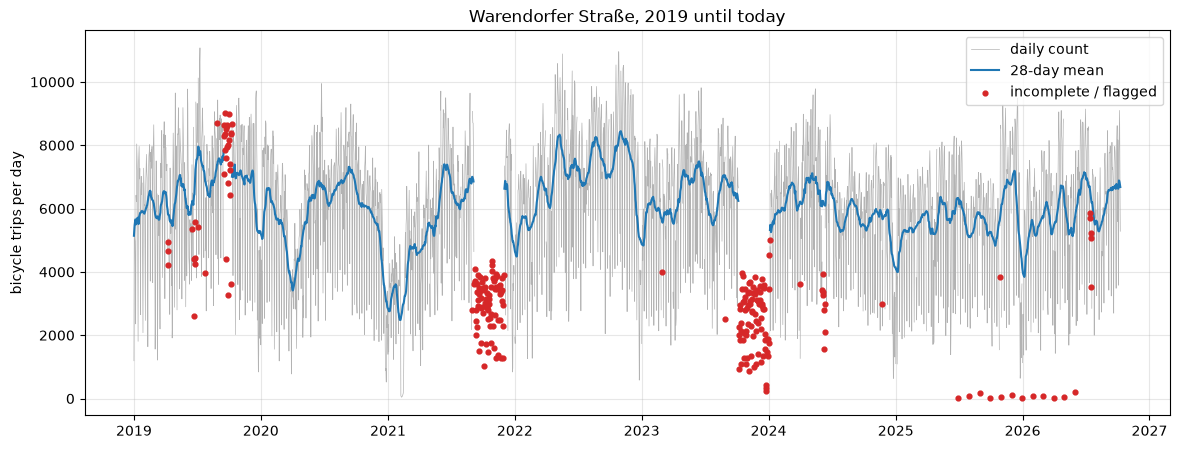

In [6]:
# Reindex to every calendar day so that excluded days become NaN.
# Otherwise matplotlib draws straight lines across the gaps, and rolling(28)
# would average 28 rows instead of 28 days.
ok = daily.loc[daily["complete"], "count"].reindex(all_days)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(ok.index, ok, lw=0.5, color="0.7", label="daily count")
# A 28-day centred rolling mean smooths out the weekly pattern;
# min_periods=14 leaves it empty where more than half of the window is missing
ax.plot(ok.index, ok.rolling(28, center=True, min_periods=14).mean(), color="C0", label="28-day mean")
ax.scatter(bad.index, bad["count"], s=12, color="C3", zorder=3, label="incomplete / flagged")
ax.set_ylabel("bicycle trips per day")
ax.set_title("Warendorfer Straße, 2019 until today")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 4. Weekly pattern

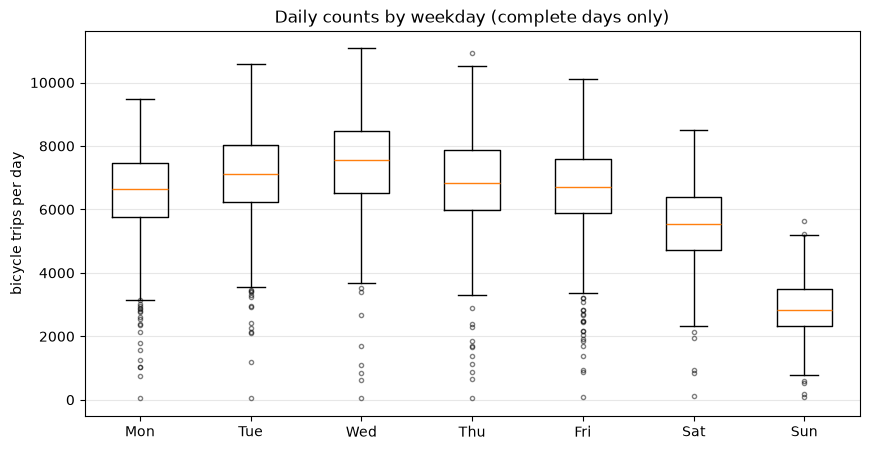

In [7]:
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

complete = daily[daily["complete"]].copy()
# dayofweek: Monday = 0, ..., Sunday = 6
complete["weekday"] = complete.index.dayofweek

fig, ax = plt.subplots(figsize=(10, 5))
# One box per weekday: the box spans the middle 50 % of days, the line is the median,
# dots beyond the whiskers are unusual days (holidays, snow, ...)
ax.boxplot(
    [complete.loc[complete["weekday"] == d, "count"] for d in range(7)],
    tick_labels=WEEKDAYS,
    flierprops={"markersize": 3, "alpha": 0.5},
)
ax.set_ylabel("bicycle trips per day")
ax.set_title("Daily counts by weekday (complete days only)")
ax.grid(axis="y", alpha=0.3)
plt.show()

In [8]:
# Median per weekday and its ratio to the median of Mon-Fri
by_weekday = complete.groupby("weekday")["count"].median().set_axis(WEEKDAYS).to_frame("median")
by_weekday["vs_workday"] = (by_weekday["median"] / by_weekday.loc["Mon":"Fri", "median"].mean()).round(2)
by_weekday

,median,vs_workday
Mon,6629.0,0.95
Tue,7122.5,1.02
Wed,7543.0,1.08
Thu,6845.0,0.98
Fri,6704.0,0.96
Sat,5552.0,0.80
Sun,2832.5,0.41


**Findings: weekly pattern**

- The weekday is the strongest effect: Sunday 0.41, Wednesday 1.08 relative to the average workday (factor 2.6).
- Wednesday and Saturday are probably higher because of the weekly market on Domplatz (hypothesis, not checked).
- The low outliers on workdays are mostly public holidays: they behave like Sundays.
- That is why the naive baseline uses the same weekday of the previous week, not the previous day.

## 5. Season

In [9]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
MIN_DAYS_PER_MONTH = 15

# Mean per year and month; months with fewer than 15 complete days become NaN,
# otherwise a handful of days (e.g. 5 days in Sep 2021) would stand for a whole month
grouped = complete["count"].groupby([complete.index.year, complete.index.month])
monthly = grouped.mean().where(grouped.size() >= MIN_DAYS_PER_MONTH).unstack()
monthly.index.name, monthly.columns.name = "year", "month"
monthly.round(-1)

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2019,5640.0,6540.0,5700.0,5830.0,6740.0,6060.0,7450.0,6890.0,7530.0,7390.0,6830.0,5910.0
2020,6290.0,5640.0,4470.0,4380.0,5900.0,6810.0,6210.0,6720.0,7240.0,6190.0,5720.0,4070.0
2021,3350.0,3010.0,4940.0,4880.0,5310.0,7370.0,6220.0,6400.0,NaN,NaN,NaN,5780.0
2022,5240.0,5390.0,7010.0,6340.0,7750.0,7430.0,6740.0,8030.0,7450.0,7580.0,8070.0,6030.0
2023,5780.0,5930.0,6020.0,6080.0,6820.0,7480.0,5690.0,6630.0,6790.0,NaN,NaN,NaN
2024,5650.0,6020.0,6540.0,6570.0,6850.0,6520.0,5620.0,5970.0,5680.0,5630.0,5810.0,4970.0
2025,4870.0,5390.0,5550.0,5410.0,6080.0,5820.0,5890.0,5440.0,5570.0,5110.0,6640.0,6000.0
2026,4770.0,5430.0,5830.0,6320.0,5250.0,6560.0,6450.0,5510.0,6750.0,NaN,NaN,NaN


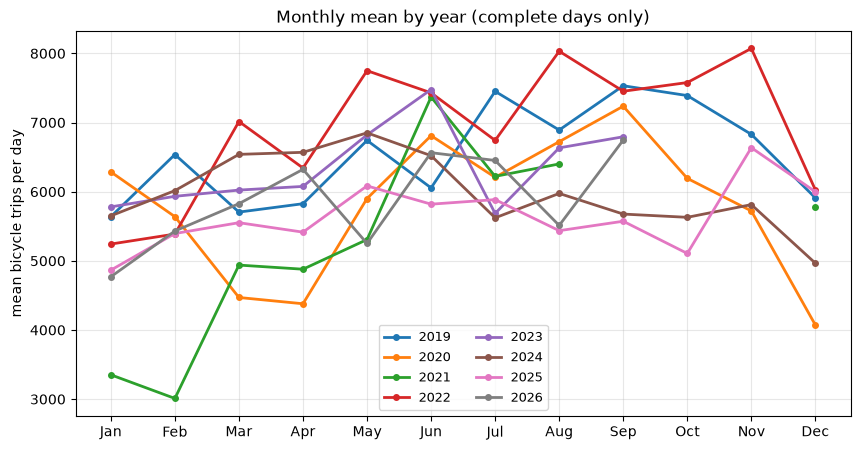

In [10]:
# One clearly distinct colour per year (matplotlib's tab10 palette)
colors = dict(zip(monthly.index, plt.cm.tab10.colors))

fig, ax = plt.subplots(figsize=(10, 5))
for year, row in monthly.iterrows():
    ax.plot(range(1, 13), row, color=colors[year], lw=2, marker="o", markersize=4, label=year)
ax.set_xticks(range(1, 13), MONTHS)
ax.set_ylabel("mean bicycle trips per day")
ax.set_title("Monthly mean by year (complete days only)")
ax.legend(ncol=2, fontsize=9)
ax.grid(alpha=0.3)
plt.show()

The absolute values mix two things: the shape of the annual curve and the level of the year.
Dividing each month by the annual mean leaves only the shape.
This only works for years with all 12 months; otherwise the annual mean is biased.

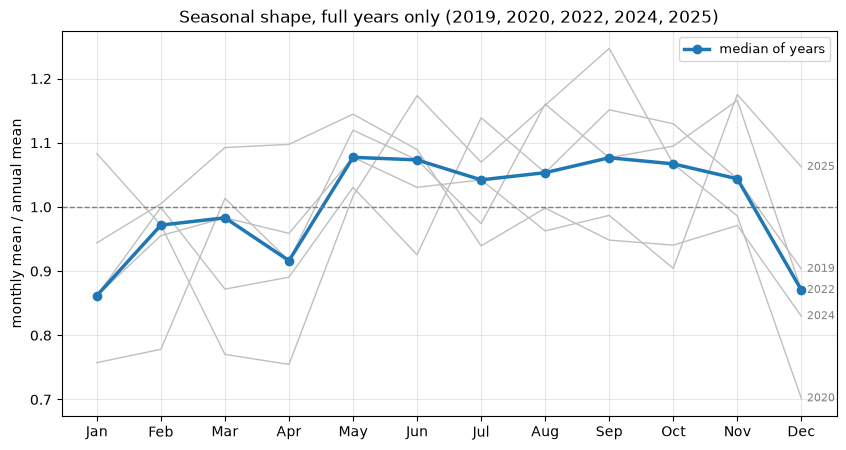

In [11]:
full_years = monthly.dropna()
# Divide each row by its own mean: 1.0 = an average month of that year
shape = full_years.div(full_years.mean(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 5))
# Single years thin and grey as context, the typical shape (median) on top
for year, row in shape.iterrows():
    ax.plot(range(1, 13), row, color="0.75", lw=1)
    ax.annotate(str(year), (12, row.iloc[-1]), xytext=(4, 0), textcoords="offset points",
                fontsize=8, color="0.5", va="center")
ax.plot(range(1, 13), shape.median(), color="C0", lw=2.5, marker="o", markersize=6, label="median of years")
ax.axhline(1, color="0.5", lw=1, ls="--")
ax.set_xticks(range(1, 13), MONTHS)
ax.set_ylabel("monthly mean / annual mean")
ax.set_title(f"Seasonal shape, full years only ({', '.join(map(str, full_years.index))})")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.show()

**Findings: season**

- The season is weaker than the weekly pattern: January and December 0.87, May and September 1.08 (factor 1.24).
- April shows a dip: Easter, school holidays and the lecture-free period until mid-April. Easter moves (end of March in 2024), so it needs its own holiday features.
- In summer, good weather (more cycling) and the semester break (fewer students) probably cancel out. Season, weather and semester are entangled; only separate features can tell them apart.
- Weekday, season and level act multiplicatively: model the logarithm of the count in a linear regression.

## 6. Autocorrelation

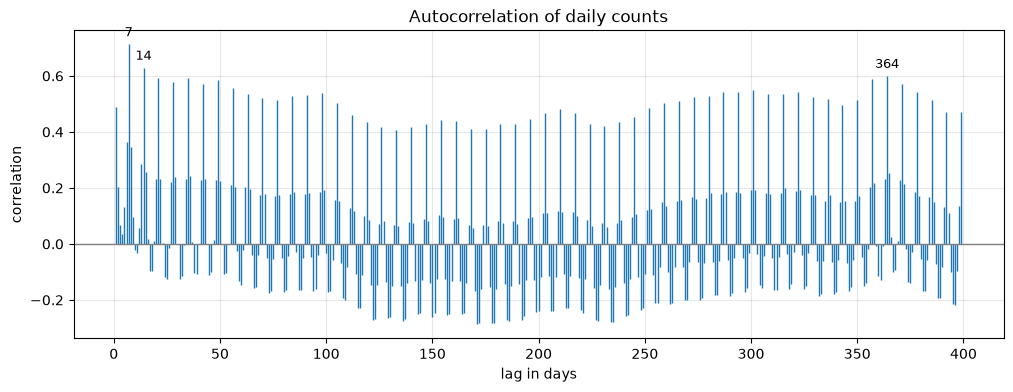

In [12]:
# Autocorrelation: how strongly is a day's count related to the count k days earlier?
# Reindex to every calendar day first, so that shift(k) really means k days and not k rows.
# Series.autocorr ignores pairs where one of the two days is NaN.
series = daily.loc[daily["complete"], "count"].reindex(all_days)
lags = range(1, 400)
acf = pd.Series([series.autocorr(lag) for lag in lags], index=lags)

fig, ax = plt.subplots(figsize=(12, 4))
ax.vlines(acf.index, 0, acf, color="C0", lw=1)
for lag in [7, 14, 364]:
    ax.annotate(f"{lag}", (lag, acf[lag]), xytext=(0, 6), textcoords="offset points",
                ha="center", fontsize=9)
ax.axhline(0, color="0.5", lw=1)
ax.set_xlabel("lag in days")
ax.set_ylabel("correlation")
ax.set_title("Autocorrelation of daily counts")
ax.grid(alpha=0.3)
plt.show()

In [13]:
acf[[1, 2, 3, 6, 7, 8, 14, 21, 28, 364, 365]].round(2).to_frame("correlation")

,correlation
1,0.49
2,0.20
3,0.07
6,0.36
7,0.71
8,0.35
14,0.63
21,0.59
28,0.58
364,0.60


**Findings: autocorrelation**

- Lag 7 has the strongest correlation (0.70); lags 14, 21, 28 stay above 0.55. The weekly cycle dominates.
- Lag 364 (0.58) is much higher than lag 365 (0.24): 364 days = 52 weeks, i.e. the same weekday a year earlier.
- Lag 1 (0.49) is weaker than lag 7, but carries the current level and weather situation.
- **Leakage:** a forecast for tomorrow is made while today is still running, so lag 1 is not available. Usable lags: 2, 7, 14, 364.

## 7. Outliers

A day is an outlier if it differs strongly from what is *typical for that weekday at that time of year*.
Expected value: median of the same weekday over ±4 weeks (9 values).
The median is robust: a single extreme day barely moves it, even though it is part of the window.

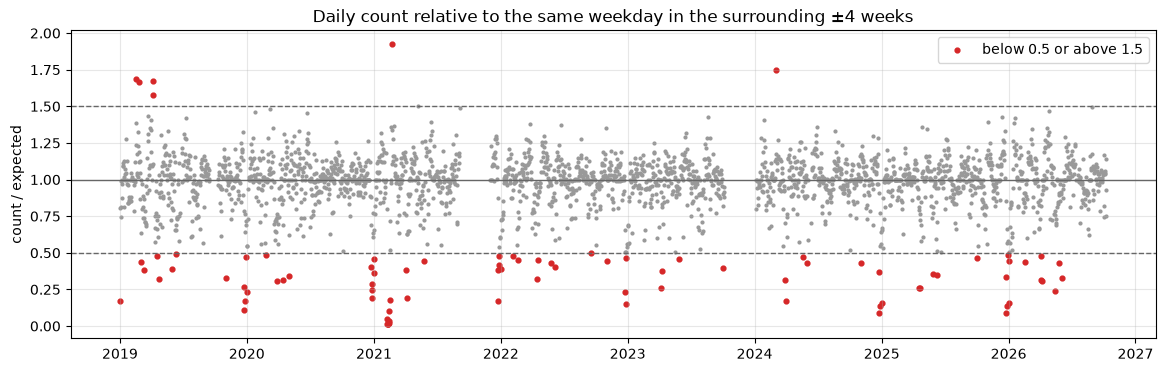

88 of 2548 days outside [0.5, 1.5]


In [14]:
# Rolling median per weekday: within one weekday, consecutive rows are exactly 7 days apart
# (series is reindexed to every calendar day), so a window of 9 rows = ±4 weeks
expected = series.groupby(series.index.dayofweek).transform(
    lambda s: s.rolling(9, center=True, min_periods=5).median()
)
ratio = (series / expected).dropna()

LOW, HIGH = 0.5, 1.5
fig, ax = plt.subplots(figsize=(14, 4))
ax.scatter(ratio.index, ratio, s=4, color="0.6")
extreme = ratio[(ratio < LOW) | (ratio > HIGH)]
ax.scatter(extreme.index, extreme, s=12, color="C3", label=f"below {LOW} or above {HIGH}")
for y in (LOW, 1, HIGH):
    ax.axhline(y, color="0.4", lw=1, ls="--" if y != 1 else "-")
ax.set_ylabel("count / expected")
ax.set_title("Daily count relative to the same weekday in the surrounding ±4 weeks")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
print(f"{len(extreme)} of {len(ratio)} days outside [{LOW}, {HIGH}]")

In [15]:
import holidays
from dateutil.easter import easter

# Label the outliers we can already explain
nrw_holidays = holidays.Germany(subdiv="NW", years=range(2019, 2027))


def reason(day: pd.Timestamp) -> str:
    if day in nrw_holidays:
        return "public holiday"
    if (day.month, day.day) in {(12, 24), (12, 31)} or (day.month == 12 and day.day >= 27):
        return "Christmas / New Year"
    if day.date() == easter(day.year) - pd.Timedelta(days=48):
        return "Rosenmontag (carnival)"
    if day.year == 2021 and day.month == 2 and day.day <= 15:
        return "snow (Feb 2021)"
    return ""


outliers = pd.DataFrame({
    "weekday": extreme.index.day_name().str[:3],
    "count": series[extreme.index].astype(int),
    "expected": expected[extreme.index].round(-1).astype(int),
    "ratio": extreme.round(2),
})
outliers["reason"] = [reason(day) for day in outliers.index]
outliers["reason"].replace("", "unexplained").value_counts()

reason
public holiday            52
unexplained               13
Christmas / New Year      11
snow (Feb 2021)            8
Rosenmontag (carnival)     4
Name: count, dtype: int64

In [16]:
# Only the outliers without a known reason
outliers[outliers["reason"] == ""].drop(columns="reason")

,weekday,count,expected,ratio
2019-02-17,Sun,3709,2200,1.69
2019-02-24,Sun,3662,2200,1.67
2019-03-10,Sun,1215,3160,0.39
2019-04-06,Sat,7401,4700,1.58
2019-04-07,Sun,4690,2800,1.68
2020-03-29,Sun,776,2530,0.31
2021-02-21,Sun,3817,1980,1.92
2022-02-06,Sun,1262,2640,0.48
2022-02-20,Sun,1273,2820,0.45
2022-09-18,Sun,2048,4100,0.50


**Findings: outliers**

- 88 days deviate by more than ±50 % from the same weekday in the surrounding ±4 weeks.
- 75 of them have a known reason: public holidays (52), Christmas to New Year (11), snow in February 2021 (8), Rosenmontag (4).
- 11 of the remaining 13 are Sundays, where leisure trips depend strongly on the weather (sunny Sundays in early spring are high, stormy ones low).
- Outliers are not errors: holidays and snow are real and stay in the data. The search did reveal a partial outage of the inbound channel (June 2024), which led to the `direction_fault` rule.

## 8. Inbound share over time

From 2022 to 2025 the level dropped. If the inbound share drops at the same time *abruptly*,
that points to the counting hardware; a *gradual* change points to a change in behaviour.

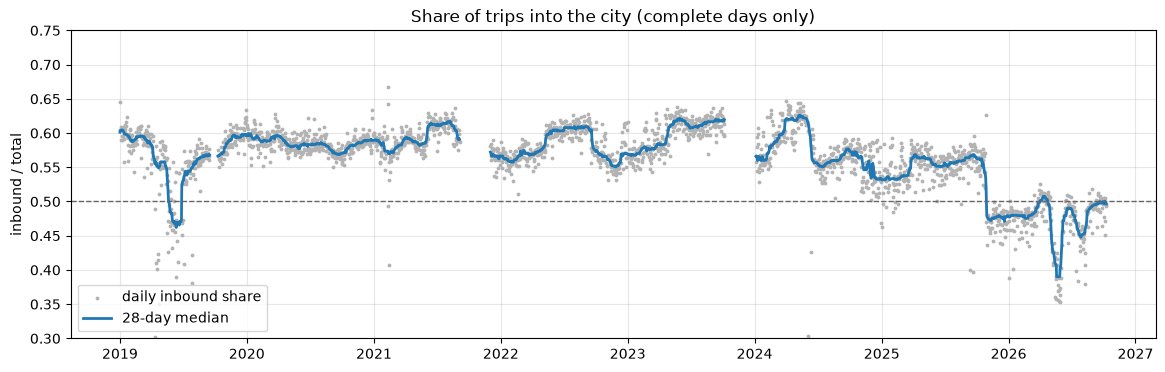

In [17]:
share = (complete["count_in"] / complete["count"]).reindex(all_days)

fig, ax = plt.subplots(figsize=(14, 4))
ax.scatter(share.index, share, s=3, color="0.7", label="daily inbound share")
ax.plot(share.index, share.rolling(28, center=True, min_periods=14).median(), color="C0", lw=2,
        label="28-day median")
ax.axhline(0.5, color="0.4", lw=1, ls="--")
ax.set_ylim(0.3, 0.75)
ax.set_ylabel("inbound / total")
ax.set_title("Share of trips into the city (complete days only)")
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.show()

In [18]:
# Median share per quarter, to read off when the change happens
share.groupby(share.index.to_period("Q")).median().round(3).to_frame("median inbound share").T

,2019Q1,2019Q2,2019Q3,2019Q4,2020Q1,2020Q2,2020Q3,2020Q4,2021Q1,2021Q2,...,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,2026Q4
median inbound share,0.595,0.519,0.56,0.591,0.592,0.583,0.578,0.584,0.582,0.593,...,0.56,0.558,0.536,0.559,0.56,0.481,0.48,0.479,0.487,0.495


**Findings: inbound share**

- The share does not drift; it jumps and then stays on the new level for months.
- Both large jumps follow a disturbance: June 2024 (0.62 → 0.55, right after the partial inbound outage of 3–11 June) and end of October 2025 (0.57 → 0.47, right after an odd day on 27 October).
- Weather cannot explain this: it affects both directions alike and does not persist for months. The likely cause is sensor maintenance or a change at the counting site.
- The two jumps differ (workday medians, 4 weeks before and after; the same weeks a year earlier as reference):
  - June 2024: inbound −14 %, outbound +8 % (a year earlier: −2 % and +1 %). Part of the lower level since 2024 is probably a measurement artefact, not fewer cyclists.
  - October 2025: inbound +20 %, outbound +67 %, total +40 % (a year earlier: +9 %, +17 %, +10 %). Counts since then are probably too high.
- Consequence: counts from different periods are not fully comparable, so the models need either recent data only or a period feature, and must be evaluated on the most recent data.